# Sieci konwolucyjne i wizja komputerowa
### Od piksela, przez konwolucję, do detekcji obiektów i segmentacji

Ten notebook to przewodnik po podstawach **wizji komputerowej** (*computer vision*) — dziedziny, która uczy komputery "widzieć". Idziemy w czterech krokach:

1. **Obraz to tylko liczby** — jak komputer przechowuje zdjęcie,
2. **Konwolucja** — serce każdej sieci konwolucyjnej (najpierw ręcznie, potem w PyTorchu),
3. **Detekcja obiektów** — znajdowanie obiektów na zdjęciu i rysowanie wokół nich ramek,
4. **Segmentacja** — malowanie dokładnej "maski" na każdym obiekcie, piksel po pikselu.

> **Ważne:** w całym notebooku **nie trenujemy żadnego modelu**. Używamy wyłącznie gotowych, wytrenowanych wcześniej sieci (tzw. *pretrained*) — nasz komputer tylko je pobiera i uruchamia. Trening wymagałby mocnej karty graficznej i wielu godzin.

**Czego potrzebujesz:** Pythona z bibliotekami `torch`, `torchvision`, `opencv-python`, `matplotlib`, `pillow`, `numpy` oraz internetu przy pierwszym uruchomieniu (do jednorazowego pobrania wag modeli, łącznie ok. 400 MB — zapisują się w pamięci podręcznej i przy kolejnych uruchomieniach nie pobierają się ponownie).

In [21]:
# Importujemy wszystkie biblioteki, których używamy w całym notebooku.
# Robimy to raz na początku, żeby każda sekcja miała do nich dostęp.
import numpy as np                # numpy = obliczenia na macierzach (obraz to macierz!)
import matplotlib.pyplot as plt   # matplotlib = rysowanie wykresów i obrazów
import torch                      # torch (PyTorch) = biblioteka do sieci neuronowych
import torch.nn as nn             # moduł nn zawiera gotowe warstwy sieci (Conv2d, Linear...)
import torchvision                # torchvision = gotowe modele i narzędzia do obrazów
import cv2                        # OpenCV = klasyczna biblioteka do przetwarzania obrazów
from PIL import Image             # PIL (Pillow) = wczytywanie obrazów z plików
import os, urllib.request         # os = operacje na plikach, urllib = pobieranie z internetu

# Ustawiamy "ziarno losowości" (seed). Sieci startują z losowymi wagami, a my
# generujemy też losowe dane testowe. Dzięki seedowi za każdym razem wyjdą TE SAME
# liczby — wyniki są powtarzalne, więc łatwo porównywać eksperymenty.
np.random.seed(42)
torch.manual_seed(42)

# PyTorch potrafi liczyć na karcie graficznej (GPU) — jest wtedy ~10x szybszy.
# Sprawdzamy, czy GPU jest dostępne; jeśli nie, liczymy na procesorze (CPU).
# Na CPU wszystko też zadziała — sekcje z gotowymi modelami będą tylko wolniejsze.
URZADZENIE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Liczymy na:", URZADZENIE)

def pokaz_obrazy(obrazy, tytuly, rozmiar=2.6):
    # Pomocnicza funkcja: pokazuje kilka obrazów obok siebie w jednym wierszu.
    fig, osie = plt.subplots(1, len(obrazy), figsize=(rozmiar * len(obrazy), rozmiar))
    osie = np.atleast_1d(osie)   # gdy jest tylko 1 obraz, dostalibyśmy pojedynczą oś zamiast listy
    for os, ob, tyt in zip(osie, obrazy, tytuly):
        if ob.ndim == 2:
            os.imshow(ob, cmap="gray")   # macierz 2D = skala szarości
        else:
            os.imshow(ob)                # macierz 3D (wysokość, szerokość, 3) = kolor RGB
        os.set_title(tyt)
        os.axis("off")                   # chowamy osie z liczbami — na obrazach są zbędne
    plt.tight_layout()
    plt.show()

PyTorch: 2.11.0+cu130 | torchvision: 0.26.0+cu130
Liczymy na: cpu


## 1. Obraz to tylko liczby

Zanim zaczniemy mówić o sieciach, musimy zrozumieć, czym dla komputera jest zdjęcie.

Kiedy patrzysz na zdjęcie, widzisz koty, domy i ludzi. Kiedy patrzy komputer, widzi **wielką tabelę z liczbami**. Każda kratka tej tabeli to jeden **piksel** — najmniejszy punkt obrazu. Liczba w kratce opisuje jasność i kolor:

- **skala szarości** — jedna liczba na piksel: `0` = czerń, `255` = biel, pomiędzy = odcienie szarości,
- **kolor (RGB)** — trzy liczby na piksel: ile czerwieni (R), zieleni (G) i błękitu (B) zmieszać, żeby dostać kolor piksela.

Rozdzielczość `1920 × 1080` oznacza po prostu: tabelę mającą 1080 wierszy i 1920 kolumn (a w kolorze — 3 takie tabele obok siebie, po jednej na każdy kanał).

Tak 'widzi' ten obraz komputer:
[[  0   0   0   0   0   0   0   0]
 [  0 255 255 255 255 255 255   0]
 [  0 255   0   0   0   0 255   0]
 [  0 255   0 255 255   0 255   0]
 [  0 255   0 255 255   0 255   0]
 [  0 255   0   0   0   0 255   0]
 [  0 255 255 255 255 255 255   0]
 [  0   0   0   0   0   0   0   0]]


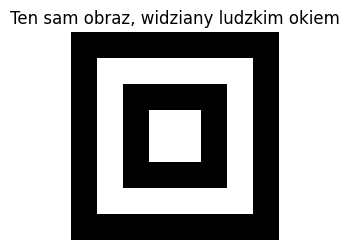

In [22]:
# Tworzymy obraz 8x8 pikseli w skali szarości jako zwykłą macierz numpy.
# Każda liczba to jasność jednego piksela: 0 = czarny, 255 = biały.
obrazek = np.array([
    [  0,   0,   0,   0,   0,   0,   0,   0],
    [  0, 255, 255, 255, 255, 255, 255,   0],
    [  0, 255,   0,   0,   0,   0, 255,   0],
    [  0, 255,   0, 255, 255,   0, 255,   0],
    [  0, 255,   0, 255, 255,   0, 255,   0],
    [  0, 255,   0,   0,   0,   0, 255,   0],
    [  0, 255, 255, 255, 255, 255, 255,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0],
], dtype=np.uint8)
# dtype=np.uint8 → "unsigned int 8-bit": liczby całkowite 0-255.
# Dokładnie ten typ danych mają prawdziwe zdjęcia zapisane w plikach JPG/PNG.

print("Tak 'widzi' ten obraz komputer:")
print(obrazek)

pokaz_obrazy([obrazek], ["Ten sam obraz, widziany ludzkim okiem"])

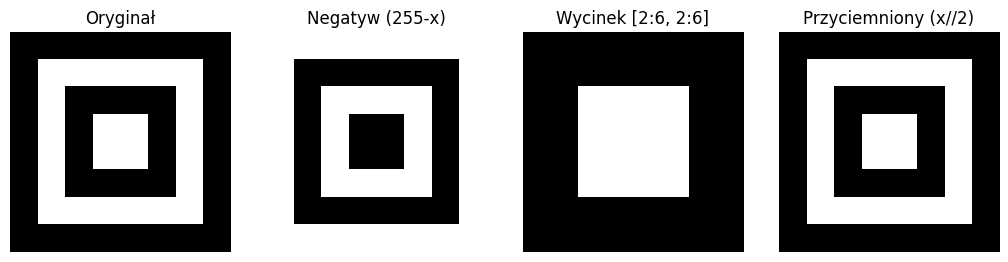

In [23]:
# Na macierzy-pikselach możemy robić zwykłą matematykę. Trzy przykłady:
negatyw     = 255 - obrazek       # odejmowanie od 255 odwraca jasność: jasne → ciemne i odwrotnie
wycinek     = obrazek[2:6, 2:6]   # indeksowanie [wiersze, kolumny] — wycinamy środek (wiersze 2-5, kolumny 2-5)
ciemniejszy = obrazek // 2        # dzielenie całkowite // zmniejsza jasność o połowę i zostaje w zakresie 0-255

pokaz_obrazy([obrazek, negatyw, wycinek, ciemniejszy],
             ["Oryginał", "Negatyw (255-x)", "Wycinek [2:6, 2:6]", "Przyciemniony (x//2)"])

## 2. Filtry — konwolucja "na wyczucie"

Zanim zbudujemy sieć, poznamy najważniejszą operację w całej wizji komputerowej: **konwolucję** (*convolution*).

Pomysł jest prosty. Bierzemy małą macierz liczb, np. 3×3, którą nazywamy **jądrem** (*kernel*) — to nasz "stempel". Przesuwamy ją po całym obrazie okienko po okienku i w każdym miejscu:

1. nakładamy jądro na 9 pikseli obrazu,
2. mnożymy każdy piksel przez odpowiadającą mu liczbę jądra,
3. sumujemy wyniki — i ta jedna suma staje się pikselem obrazu wyjściowego.

Cała sztuka polega na tym, **jakie liczby wpisujemy do jądra**:

| Co w jądrze | Efekt |
|---|---|
| wszystko `1/9` | uśrednianie sąsiadów → **rozmycie** |
| `5` w środku, `-1` dookoła | środek wzmocniony, sąsiedzi odejmowani → **wyostrzenie** |
| po lewej `-`, po prawej `+` | reaguje na różnice lewo–prawo → **wykrywanie pionowych krawędzi** |

Kluczowa obserwacja: **ten sam mechanizm, różne liczby — zupełnie różne efekty**. Sieć konwolucyjna to pomysł: *"nie wymyślajmy liczb do jąder ręcznie — niech sieć nauczy się ich sama"*. Do tego wrócimy w sekcji 4.

Na razie potrzebujemy jakiegoś obrazu do testów. Wygenerujemy go sami, rysując prosto po macierzy numpy — to dobry trening myślenia "obraz = tabela liczb":

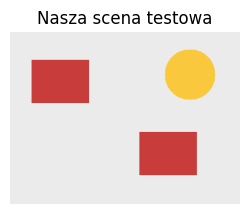

In [24]:
def zbuduj_scene(wysokosc=240, szerokosc=320):
    # Budujemy scenę bez plików i bez internetu — rysujemy bezpośrednio na macierzy numpy.
    scena = np.full((wysokosc, szerokosc, 3), 235, dtype=np.uint8)
    # np.full tworzy macierz wypełnioną jedną wartością: (wysokość, szerokość, 3 kanały RGB) = 235 (jasny szary)

    # Prostokąt nr 1 ("dom"): wiersze 40-99, kolumny 30-109 — wpisujemy kolor wprost do wycinka macierzy
    scena[40:100, 30:110] = (200, 60, 60)    # czerwony (R, G, B)

    # Prostokąt nr 2 ("samochód"): ten sam kolor, inne miejsce. Świadomie dwa obiekty tego samego
    # koloru — przyda się w sekcji 10, żeby pokazać różnicę między segmentacją semantyczną a instancji
    scena[140:200, 180:260] = (200, 60, 60)

    # Koło ("słońce"): dla każdego piksela sprawdzamy (Pitagoras!), czy leży w promieniu 35 od środka
    Y, X = np.ogrid[:wysokosc, :szerokosc]   # dwie macierze współrzędnych: Y = numer wiersza, X = numer kolumny
    maska_kola = (X - 250)**2 + (Y - 60)**2 <= 35**2   # True tam, gdzie piksel jest w kole
    scena[maska_kola] = (250, 200, 60)       # żółty — wpisujemy kolor tylko w piksele maski
    return scena

scena = zbuduj_scene()
pokaz_obrazy([scena], ["Nasza scena testowa"])

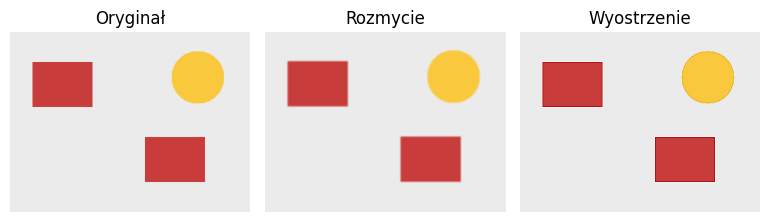

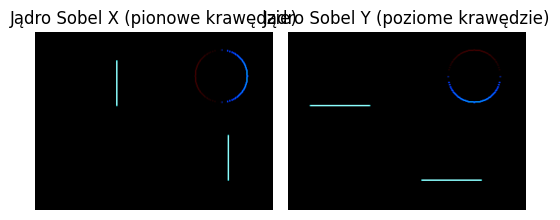

In [25]:
# Definiujemy jądra jako małe macierze numpy. Każde jądro to "przepis" na inny efekt.
jadro_rozmycia = np.array([[1, 1, 1],
                           [1, 1, 1],
                           [1, 1, 1]], dtype=np.float32) / 9.0
# Dzielimy przez 9, żeby suma wag wynosiła 1 → obraz nie zmienia jasności, tylko się rozmywa.

jadro_wyostrzenia = np.array([[ 0, -1,  0],
                              [-1,  5, -1],
                              [ 0, -1,  0]], dtype=np.float32)
# Środek ma wagę 5, sąsiedzi -1: piksel staje się "odległy" od sąsiadów → krawędzie ostrejsze.

jadro_sobel_x = np.array([[-1, 0, 1],
                          [-2, 0, 2],
                          [-1, 0, 1]], dtype=np.float32)
# Po lewej ujemne, po prawej dodatnie → jądro reaguje, gdy jasność rośnie od lewej do prawej,
# czyli wykrywa PIONOWE krawędzie (np. boki prostokątów).

jadro_sobel_y = np.array([[-1, -2, -1],
                          [ 0,  0,  0],
                          [ 1,  2,  1]], dtype=np.float32)
# To samo, ale obrócone o 90° → wykrywa POZIOME krawędzie (np. góra i dół prostokątów).

# cv2.filter2D nakłada jądro na obraz dokładnie tak, jak opisaliśmy w tekście.
# Wywołanie: filter2D(obraz, ddepth, jadro)
#   ddepth=-1 → "głębokość (typ) wyniku taka sama jak wejścia" — niczego nie konwertujemy ręcznie
rozmyta    = cv2.filter2D(scena, -1, jadro_rozmycia)
wyostrzona = cv2.filter2D(scena, -1, jadro_wyostrzenia)
pionowe    = cv2.filter2D(scena, -1, jadro_sobel_x)
poziome    = cv2.filter2D(scena, -1, jadro_sobel_y)

pokaz_obrazy([scena, rozmyta, wyostrzona], ["Oryginał", "Rozmycie", "Wyostrzenie"])
pokaz_obrazy([pionowe, poziome], ["Jądro Sobel X (pionowe krawędzie)", "Jądro Sobel Y (poziome krawędzie)"])
# Na mapach Sobela krawędzie wyglądają jak jasne linie na czarnym tle: tam, gdzie jasność się zmienia,
# suma iloczynów jest duża; na jednolitym tle (np. w środku prostokąta) sąsiedzi się "znoszą" → 0.

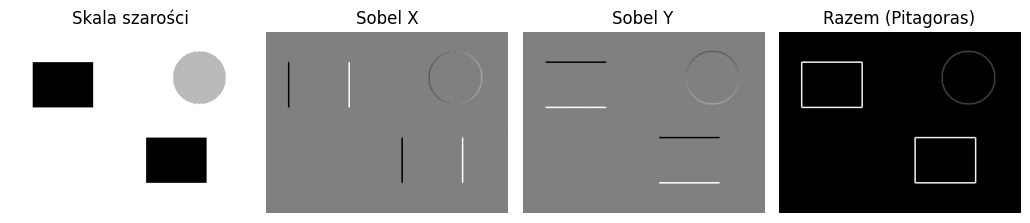

In [26]:
# Krawędzie najlepiej szukać na obrazie w skali szarości — kolor nas tu nie interesuje,
# a jedna macierz zamiast trzech to trzy razy mniej liczenia.
szara = cv2.cvtColor(scena, cv2.COLOR_RGB2GRAY).astype(np.float32)
# cvtColor konwertuje RGB → 1 kanał jasności; astype(float32) — liczymy na liczbach zmiennoprzecinkowych,
# żeby ujemne wyniki (Sobel potrafi zwracać wartości < 0) nie zostały obcięte do zera jak w typie uint8

gx = cv2.filter2D(szara, -1, jadro_sobel_x)   # reaguje na pionowe krawędzie
gy = cv2.filter2D(szara, -1, jadro_sobel_y)   # reaguje na poziome krawędzie

# Krawędź jest tam, gdzie reaguje KTÓREKOLWIEK jądro. Łączymy oba wyniki twierdzeniem
# Pitagorasa (jak długość wektora (gx, gy)) — to standardowy sposób łączenia dwóch Sobeli:
krawedzie = np.sqrt(gx**2 + gy**2)

pokaz_obrazy([szara, gx, gy, krawedzie],
             ["Skala szarości", "Sobel X", "Sobel Y", "Razem (Pitagoras)"])

## 3. Konwolucja od zera — zobaczmy, co dzieje się w środku

OpenCV robi konwolucję za nas (bardzo szybko, w skompilowanym kodzie). Ale żeby naprawdę zrozumieć sieci konwolucyjne, napiszmy ją **samodzielnie w numpy** — wolno, prosto i jawnie.

Nasza wersja przyjmuje parametry, które spotkasz w **każdej** sieci konwolucyjnej:

- **`krok`** (*stride*) — co ile pikseli przesuwamy okno. `1` = co piksel (gęsto), `2` = co drugi (wynik 2× mniejszy),
- **`padding`** — ile pierścieni zer doklejamy dookoła obrazu. Bez paddingu obraz 6×6 po jądrze 3×3 zmniejszy się do 4×4 (okno nie mieści się przy brzegach). Padding `1` "ratuje" rozmiar,
- **jądro** — te małe wagi, które w prawdziwej sieci będą się uczyć.

Rozmiar wyniku liczy się zawsze tym samym wzorem:

$$\text{wyjście} = \left\lfloor \frac{\text{wejście} + 2 \cdot \text{padding} - \text{jądro}}{\text{krok}} \right\rfloor + 1$$

In [27]:
def konwolucja2d(obraz, jadro, krok=1, padding=0):
    # Najprostsza (i najwolniejsza) konwolucja 2D — napisana jawnie, żeby zobaczyć mechanikę.
    # obraz:   macierz 2D numpy (wysokość, szerokość) — pracujemy na jednym kanale
    # jadro:   macierz 2D numpy, np. 3x3 — "filtr", który przesuwamy po obrazie
    # krok:    co ile pikseli przesuwamy okno (1 = co piksel, 2 = co drugi)
    # padding: ile pierścieni zer doklejamy z każdej strony obrazu

    wys_j, szer_j = jadro.shape          # wymiary jądra, np. 3 i 3

    if padding > 0:
        # np.pad dokleja "padding" warstw zer z każdej strony (góra, dół, lewo, prawo)
        obraz = np.pad(obraz, padding, mode="constant", constant_values=0)

    # Wzór na rozmiar wyniku — ten sam, którego używają wszystkie frameworki!
    # (obraz ma już doliczony padding, więc "wejście + 2*padding" to po prostu obraz.shape)
    wys_w  = (obraz.shape[0] - wys_j) // krok + 1
    szer_w = (obraz.shape[1] - szer_j) // krok + 1
    wynik = np.zeros((wys_w, szer_w))    # przygotowujemy pustą macierz na wynik

    for y in range(wys_w):               # przesuwamy okno w dół...
        for x in range(szer_w):          # ...i w prawo
            # wycinamy okno obrazu, na które aktualnie "nachodzi" jądro
            okno = obraz[y*krok : y*krok + wys_j,
                         x*krok : x*krok + szer_j]
            # mnożymy piksel po pikselu (okno × jądro) i sumujemy 9 (lub 25...) iloczynów
            wynik[y, x] = np.sum(okno * jadro)
    return wynik

# Ciekawostka: formalna konwolucja z matematyki każe najpierw obrócić jądro o 180°.
# W praktyce sieci neuronowe i OpenCV tego NIE robią (robią tzw. korelację) — a dla
# symetrycznych jąder nie ma to żadnego znaczenia. My też nie obracamy, więc nasz wynik
# będzie się zgadzał z PyTorchem i OpenCV.

In [28]:
# Mały obraz 6x6 (liczby 0..35 ułożone w tabelę) i nasze jądro Sobel X:
maly_obraz = np.arange(36, dtype=np.float32).reshape(6, 6)
jadro = np.array([[1, 0, -1],
                  [2, 0, -2],
                  [1, 0, -1]], dtype=np.float32)

wynik = konwolucja2d(maly_obraz, jadro)
print("Obraz 6x6, jądro 3x3, krok=1, padding=0 → wynik ma rozmiar:", wynik.shape)

# Sprawdźmy, czy nasza "ręczna" wersja zgadza się z profesjonalną implementacją OpenCV.
# Różnica: OpenCV inaczej obsługuje brzegi (odbija obraz zamiast dopisywać zera), więc
# porównujemy tylko środek wyniku, gdzie brzegi nie mają znaczenia.
z_opencv = cv2.filter2D(maly_obraz, -1, jadro)[1:-1, 1:-1]   # [1:-1, 1:-1] = obcięcie brzegowego piksela z każdej strony
print("Maksymalna różnica względem OpenCV:", np.abs(wynik - z_opencv).max(), "(powinno być 0.0)")

# Sprawdźmy wzór na rozmiar wyniku dla różnych ustawień (obraz 6x6, jądro 3x3):
for krok, padding in [(1, 0), (1, 1), (2, 0), (2, 1)]:
    w = konwolucja2d(maly_obraz, np.ones((3, 3), np.float32), krok=krok, padding=padding)
    przewidziane = (6 + 2 * padding - 3) // krok + 1
    print(f"krok={krok}, padding={padding} → wynik {w.shape[0]}x{w.shape[1]} (wzór przewidział: {przewidziane}x{przewidziane})")

Obraz 6x6, jądro 3x3, krok=1, padding=0 → wynik ma rozmiar: (4, 4)
Maksymalna różnica względem OpenCV: 0.0 (powinno być 0.0)
krok=1, padding=0 → wynik 4x4 (wzór przewidział: 4x4)
krok=1, padding=1 → wynik 6x6 (wzór przewidział: 6x6)
krok=2, padding=0 → wynik 2x2 (wzór przewidział: 2x2)
krok=2, padding=1 → wynik 3x3 (wzór przewidział: 3x3)


## 4. Bloki CNN w PyTorch — te same klocki, ale uczące się

Mamy już intuicję. Teraz zamieniamy ją na prawdziwe narzędzia. **PyTorch** to biblioteka, w której buduje się sieci neuronowe — jej moduł `torch.nn` zawiera gotowe warstwy.

Trzy najważniejsze klocki sieci konwolucyjnej (CNN — *Convolutional Neural Network*):

1. **`nn.Conv2d`** — warstwa konwolucyjna. Różnica względem sekcji 2: **nie wpisujemy liczb do jądra sami** — jądra to zmienne (tzw. *wagi*), których wartości sieć **nauczy się** podczas treningu. Jedna warstwa ma od razu wiele jąder — każde może nauczyć się wykrywać coś innego (krawędź, łuk, teksturę...).
2. **`nn.ReLU`** — najprostsza "aktywacja": ujemne wartości zamienia na zera, dodatnie zostawia. Po co? Bez niej cała sieć (same mnożenia i sumy) zwinęłaby się do jednej wielkiej operacji liniowej. ReLU wprowadza nieliniowość — "załamania", dzięki którym sieć może uczyć się złożonych kształtów.
3. **`nn.MaxPool2d`** — zmniejsza obraz 2×, zostawiając w każdym oknie 2×2 tylko największą wartość. Efekt: mniej liczenia i **odporność na drobne przesunięcia** — jeśli krawędź przesunie się o 1 piksel, maksimum w oknie i tak zostanie złapane.

> Uwaga: w tym notebooku **nie trenujemy** — wagi warstw będą losowe, więc wyniki sieci będą "bez sensu". Ale mechanika (kształty danych, liczba parametrów) działa dokładnie tak samo jak w wytrenowanej sieci.

In [29]:
# Anatomia warstwy konwolucyjnej:
warstwa = nn.Conv2d(in_channels=1, out_channels=4, kernel_size=3, padding=1)
# in_channels=1   → każdy piksel wejścia ma 1 liczbę (skala szarości; dla koloru byłoby 3: R, G, B)
# out_channels=4  → warstwa ma 4 RÓŻNE jądra, czyli nauczy się 4 różnych "wykrywaczy wzorców"
# kernel_size=3   → każde jądro to okno 3x3
# padding=1       → doklejamy 1 pierścień zer, żeby mapa nie zmniejszyła się (dla jądra 3x3 to standard)

print("Wagi (jądra):", tuple(warstwa.weight.shape))
# [4, 1, 3, 3] czytamy tak: 4 jąder, każde patrzy na 1 kanał wejścia, wymiary 3x3
print("Bias (przesunięcia):", tuple(warstwa.bias.shape))
# [4] — każde jądro ma jeszcze jedną liczbę, dodawaną do sumy (jak wyraz wolny w a·x + b)

# Policzmy parametry ręcznie i porównajmy z tym, co mówi PyTorch:
recznie = 4 * 1 * 3 * 3 + 4          # (ile_jader × na_ilu_kanałach × wys × szer) + biasy
print("Parametry policzone ręcznie:", recznie)
print("Parametry wg PyTorcha:      ", warstwa.weight.numel() + warstwa.bias.numel())
# .numel() = "number of elements" — liczba elementów tensora

# Przepuśćmy przez warstwę "fałszywy obraz" 8x8 (jeden kanał) — losowe liczby zamiast prawdziwego zdjęcia:
x = torch.rand(1, 1, 8, 8)
# wymiary tensora: (1 obraz, 1 kanał, 8 wysokości, 8 szerokości).
# PyTorch zawsze dodaje pierwszy wymiar "partii" (batch) — sieci liczą wiele obrazów naraz.

y = warstwa(x)
print("Wejście:", tuple(x.shape), "→ Wyjście:", tuple(y.shape))
# 8x8 → 8x8: padding=1 zrekompensował jądro 3x3, a 4 kanały wyjścia = 4 jądra

Wagi (jądra): (4, 1, 3, 3)
Bias (przesunięcia): (4,)
Parametry policzone ręcznie: 40
Parametry wg PyTorcha:       40
Wejście: (1, 1, 8, 8) → Wyjście: (1, 4, 8, 8)


In [30]:
# Mały tensor 4x4 z liczbami dodatnimi i ujemnymi — zobaczmy dokładnie, co robią ReLU i MaxPool:
x = torch.tensor([[[[-1.,  2., -3.,   4.],
                    [ 5., -6.,  7.,  -8.],
                    [-9., 10., -11., 12.],
                    [13., -14., 15., -16.]]]])
# cztery nawiasy = cztery wymiary: (1 obraz, 1 kanał, 4 wysokości, 4 szerokości) —
# dokładnie taki układ danych płynie przez prawdziwe sieci konwolucyjne

print("Wejście:\n", x[0, 0])            # x[0, 0] = wyjmujemy jedyny obraz i jedyny kanał, żeby ładnie wydrukować
print("\nPo ReLU (ujemne → 0):\n", nn.ReLU()(x)[0, 0])
print("\nPo MaxPool2d(2) (max z każdego okna 2x2):\n", nn.MaxPool2d(kernel_size=2)(x)[0, 0])
# MaxPool2d(kernel_size=2) domyślnie ma też krok (stride) równy 2 → obraz zmniejsza się dokładnie 2x

Wejście:
 tensor([[ -1.,   2.,  -3.,   4.],
        [  5.,  -6.,   7.,  -8.],
        [ -9.,  10., -11.,  12.],
        [ 13., -14.,  15., -16.]])

Po ReLU (ujemne → 0):
 tensor([[ 0.,  2.,  0.,  4.],
        [ 5.,  0.,  7.,  0.],
        [ 0., 10.,  0., 12.],
        [13.,  0., 15.,  0.]])

Po MaxPool2d(2) (max z każdego okna 2x2):
 tensor([[ 5.,  7.],
        [13., 15.]])


## 5. Składamy małą sieć konwolucyjną

Typowa sieć konwolucyjna to **kanapka** z powtarzających się warstw:

```
[Conv → ReLU → Pool] → [Conv → ReLU → Pool] → ... → Flatten → Linear
```

- blok **Conv → ReLU → Pool** wyciąga z obrazu coraz bardziej złożone wzorce: pierwsze warstwy widzą krawędzie i plamki, kolejne — rogi i łuki, ostatnie — całe kształty (koła, okna, twarze),
- **`nn.Flatten`** rozplata wszystkie mapy cech w jeden długi wektor liczb,
- **`nn.Linear`** (warstwa w pełni połączona) patrzy na ten wektor i "głosuje" — po jednej liczbie na każdą klasę (np. 10 klas = 10 wyjść).

Zbudujemy sieć dla obrazków 64×64 w skali szarości i 10 klasach — i **prześledzimy, jak zmienia się kształt danych** na każdym etapie.

In [31]:
from collections import OrderedDict

# nn.Sequential to "pociąg" warstw: dane wjeżdżają na początku i przepływają przez każdą po kolei.
# OrderedDict nadaje warstwom nazwy — dzięki temu łatwo je potem wypisywać.
model = nn.Sequential(OrderedDict([
    # Blok 1: 1 kanał (szarość) → 8 map cech; obraz 64x64 zostaje 64x64 (padding=1)
    ("konw1",    nn.Conv2d(1, 8, kernel_size=3, padding=1)),
    ("relu1",    nn.ReLU()),
    ("pool1",    nn.MaxPool2d(2)),                     # 64x64 → 32x32
    # Blok 2: 8 kanałów → 16 map cech; obraz 32x32 zostaje 32x32
    ("konw2",    nn.Conv2d(8, 16, kernel_size=3, padding=1)),
    ("relu2",    nn.ReLU()),
    ("pool2",    nn.MaxPool2d(2)),                     # 32x32 → 16x16
    # Rozplatanie: 16 map 16x16 = 16*16*16 = 4096 liczb w jednym wektorze
    ("splaszcz", nn.Flatten()),
    # Klasyfikator: 4096 wejść → 10 wyników (po jednym na klasę)
    ("wyjscie",  nn.Linear(16 * 16 * 16, 10)),
]))

# "Fałszywe zdjęcie": 1 obraz, 1 kanał, 64x64, wartości losowe 0-1
x = torch.rand(1, 1, 64, 64)

# Przepuszczamy dane warstwa po warstwie i wypisujemy kształt po każdej z nich.
# To DOKŁADNIE to samo, co robi wywołanie model(x) — tylko z podglądem pod maską.
for nazwa, warstwa in model.named_children():
    x = warstwa(x)
    print(f"{nazwa:10s} → kształt: {tuple(x.shape)}")

konw1      → kształt: (1, 8, 64, 64)
relu1      → kształt: (1, 8, 64, 64)
pool1      → kształt: (1, 8, 32, 32)
konw2      → kształt: (1, 16, 32, 32)
relu2      → kształt: (1, 16, 32, 32)
pool2      → kształt: (1, 16, 16, 16)
splaszcz   → kształt: (1, 4096)
wyjscie    → kształt: (1, 10)


In [32]:
# Ile tej sieci jest "śrubek" (parametrów, które mogłyby się uczyć)?
ile_parametrow = sum(p.numel() for p in model.parameters())
print("Parametrów w sumie:", ile_parametrow)

# Sprawdźmy ręcznie, czy się zgadza:
#   konw1:    8 jąder × 1 kanał × 3x3 + 8 biasów    = 80
#   konw2:   16 jąder × 8 kanałów × 3x3 + 16 biasów = 1168
#   wyjscie: 4096 wejść × 10 wyjść + 10 biasów      = 40970
print("Ręcznie: 80 + 1168 + 40970 =", 80 + 1168 + 40970)

# Ciekawostka: prawie wszystkie parametry siedzą w ostatniej warstwie Linear.
# To typowe — "myślenie" (klasyfikacja) jest droższe niż "patrzenie" (konwolucje).

def rozmiar_po_konwolucji(rozmiar, jadro, padding=0, krok=1):
    # Wzór z sekcji 3, teraz jako funkcja — przydaje się przy planowaniu architektury
    return (rozmiar + 2 * padding - jadro) // krok + 1

print("64 po konwolucji (jądro 3, padding 1):", rozmiar_po_konwolucji(64, 3, padding=1))   # 64 — padding ratuje rozmiar
print("64 po pool 2x2:                     ", rozmiar_po_konwolucji(64, 2, krok=2))        # 32

Parametrów w sumie: 42218
Ręcznie: 80 + 1168 + 40970 = 42218
64 po konwolucji (jądro 3, padding 1): 64
64 po pool 2x2:                      32


## 6. Gotowy, wytrenowany model — klasyfikacja zdjęcia

Nasza mała sieć ma losowe wagi, więc niczego nie rozpozna. Ale ktoś już kiedyś wytrenował za nas ogromne sieci na milionach zdjęć — i te wagi są **publicznie dostępne**. My tylko je pobieramy i używamy.

Użyjemy **ResNet-18** — klasycznej architektury z 2015 roku, wytrenowanej na zbiorze **ImageNet**: 1,2 mln zdjęć, 1000 klas (psy, koty, samochody, banany...).

Zwróć uwagę na **przygotowanie obrazu** — sieć wymaga zdjęć dokładnie w takiej formie, w jakiej była trenowana:
- przeskalowanie do 256 px i wycięcie środka 224×224 (takiego rozmiaru oczekuje architektura),
- zamiana na tensor (liczby 0–1 zamiast 0–255),
- **normalizacja** — od każdej wartości odejmujemy średnią i dzielimy przez odchylenie standardowe ze zbioru ImageNet. Bez tego sieć dostaje "zdjęcia" w dziwnej skali i myli się.

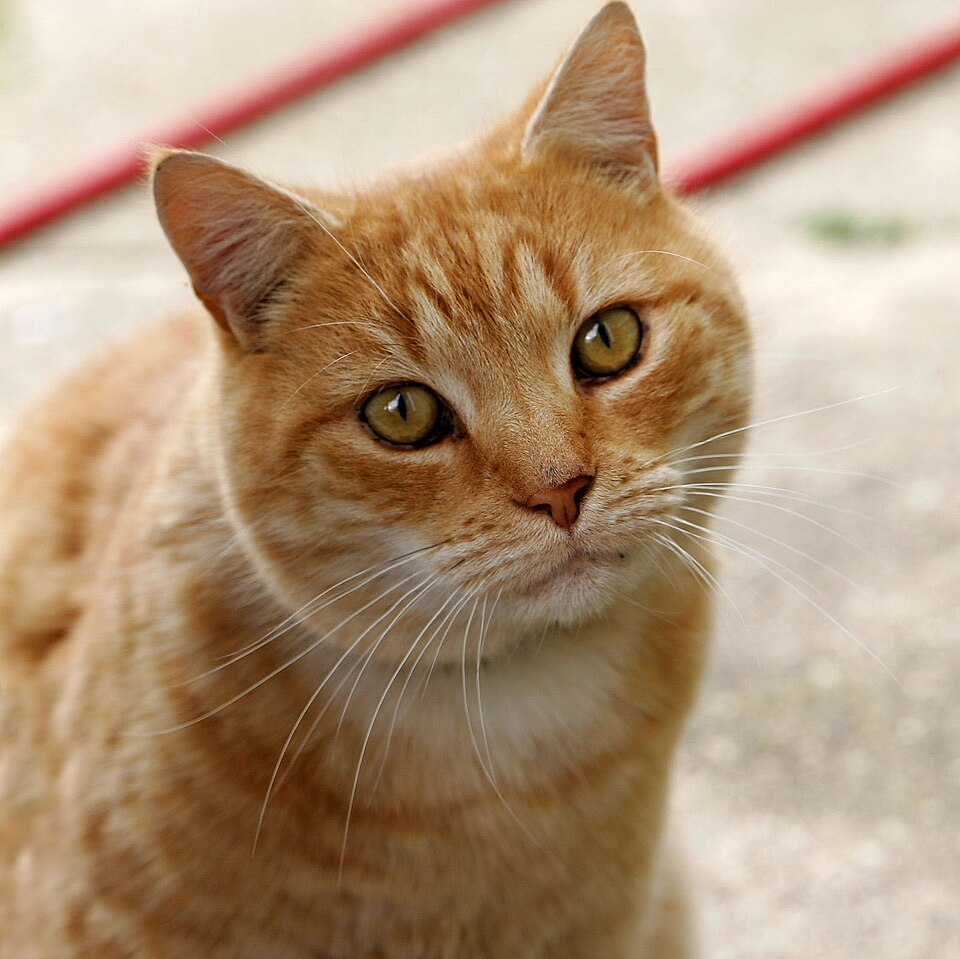

In [33]:
# Jeśli masz własne zdjęcie, wpisz tutaj jego nazwę (plik obok notebooka), np.:
# WLASNY_OBRAZ = "ja.jpg"
WLASNY_OBRAZ = None

def pobierz_plik(url, sciezka):
    # Pobiera plik z internetu, ale tylko raz — jeśli już istnieje na dysku, pomijamy pobieranie
    if os.path.exists(sciezka):
        return sciezka
    # Niektóre serwery (np. Wikimedia) odrzucają żądania bez nagłówka User-Agent — dodajemy go
    zadanie = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(zadanie) as odpowiedz:
        dane = odpowiedz.read()      # czytamy całość do pamięci...
    with open(sciezka, "wb") as plik:
        plik.write(dane)             # ...i dopiero teraz zapisujemy — plik na dysku zawsze będzie kompletny
    return sciezka

def wczytaj_obraz_demo():
    # Zwraca obraz PIL. Kolejność prób:
    #  1. własne zdjęcie (jeśli ustawiłeś WLASNY_OBRAZ powyżej),
    #  2. zdjęcie kota z Wikimedia Commons,
    #  3. zdjęcie psa z serwisu picsum,
    #  4. awaryjnie: nasza narysowana scena (sieć może wtedy nic ciekawego nie rozpoznać)
    if WLASNY_OBRAZ and os.path.exists(WLASNY_OBRAZ):
        print("Używam Twojego zdjęcia:", WLASNY_OBRAZ)
        return Image.open(WLASNY_OBRAZ).convert("RGB")
    for url, nazwa in [("https://commons.wikimedia.org/wiki/Special:FilePath/Cat03.jpg?width=800", "obraz_demo.jpg"),
                       ("https://picsum.photos/id/237/640/480", "obraz_demo.jpg")]:
        try:
            pobierz_plik(url, nazwa)
            return Image.open(nazwa).convert("RGB")
        except Exception as blad:
            print(f"Nie udało się pobrać {url} → {blad}")
            if os.path.exists(nazwa):
                os.remove(nazwa)     # usuwamy uszkodzony plik, żeby następna próba pobrała od zera
    print("Brak internetu — rysuję scenę awaryjną")
    return Image.fromarray(zbuduj_scene())

obraz_pil = wczytaj_obraz_demo()
obraz_pil   # ostatnia linia komórki = wyświetlenie obrazu w notebooku

Co widzi ResNet-18:
  tiger cat                  41.0%
  Egyptian cat               39.4%
  tabby                      15.5%
  lynx                        2.1%
  mouse                       0.2%


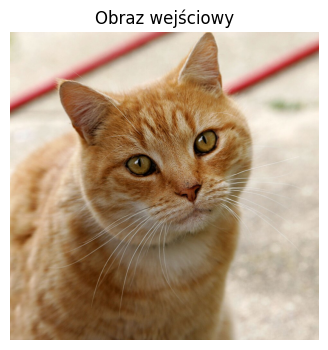

In [34]:
# Pobieramy architekturę + gotowe wagi. "DEFAULT" znaczy: "daj najlepsze dostępne wytrenowane wagi".
# Pierwsze uruchomienie pobiera ok. 45 MB do ~/.cache/torch — kolejne są natychmiastowe.
wagi = torchvision.models.ResNet18_Weights.DEFAULT
model_klasyfikator = torchvision.models.resnet18(weights=wagi)
model_klasyfikator.eval()            # tryb "tylko używanie": wyłącza zachowania przydatne tylko przy treningu
model_klasyfikator.to(URZADZENIE)    # przenosimy model na GPU, jeśli jest (na CPU też zadziała)

# Przygotowanie obrazu — dokładnie taki "przepis", jakiego użyto przy treningu:
transformacja = torchvision.transforms.Compose([
    torchvision.transforms.Resize(256),        # krótszy bok zdjęcia → 256 px (proporcje zachowane)
    torchvision.transforms.CenterCrop(224),    # wycinamy środek 224x224 — taki rozmiar oczekuje ResNet
    torchvision.transforms.ToTensor(),         # obraz PIL → tensor: wartości 0-255 → 0-1, kolejność (kanał, wys, szer)
    torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406],   # średnie z ImageNet (osobno dla R, G, B)
                                     std=[0.229, 0.224, 0.225]),   # odchylenia z ImageNet — "wycentrowanie" danych
])

tensor = transformacja(obraz_pil).unsqueeze(0).to(URZADZENIE)
# unsqueeze(0) dokleja wymiar partii: (3, 224, 224) → (1, 3, 224, 224) — sieci oczekują "stosu" obrazów

with torch.inference_mode():   # mówimy PyTorchowi: nie śledź niczego do nauki → mniej pamięci, szybciej
    wyniki = model_klasyfikator(tensor)                    # 1000 surowych "głosów", po jednym na klasę
    prawdopodobienstwa = torch.softmax(wyniki, dim=1)[0]   # softmax zamienia głosy na procenty (suma = 100%)
    # dim=1 → softmax liczymy wzdłuż wymiaru klas (a nie partii)

# Wagi pamiętają nazwy wszystkich 1000 klas — wyciągamy je z metadanych:
kategorie = wagi.meta["categories"]
top5 = torch.topk(prawdopodobienstwa, k=5)   # 5 najwyższych prawdopodobieństw (wartości + indeksy klas)

print("Co widzi ResNet-18:")
for wartosc, indeks in zip(top5.values, top5.indices):
    print(f"  {kategorie[indeks.item()]:25s} {wartosc.item() * 100:5.1f}%")

plt.figure(figsize=(4, 4))
plt.imshow(obraz_pil); plt.axis("off"); plt.title("Obraz wejściowy")
plt.show()

## 7. Detekcja obiektów — koncepcja

Klasyfikator odpowiada na jedno pytanie: **"co jest na zdjęciu?"**. Detektor odpowiada na trudniejsze: **"co jest na zdjęciu i GDZIE?"**.

Wynik detekcji to lista obiektów, a każdy obiekt opisują trzy rzeczy:
1. **ramka** (*bounding box*) — prostokąt "opasujący" obiekt, podany jako 4 liczby: `x1, y1` (lewy górny róg) i `x2, y2` (prawy dolny),
2. **etykieta** — nazwa klasy ("kot", "osoba", "samochód"),
3. **pewność** (*score*) — liczba 0–1: jak bardzo detektor jest pewny, że to faktycznie obiekt.

Zanim sięgniemy po sieć, poznajemy dwa "matematyczne narzędzia", bez których nie działa żaden detektor:

**IoU (Intersection over Union)** — miara pokrycia dwóch ramek: pole przecięcia dzielone przez pole sumy (unii). `1.0` = ramki identyczne, `0` = rozłączne. IoU służy do dwóch rzeczy: do oceny, czy wykryta ramka trafiła w obiekt, i do usuwania duplikatów.

**NMS (Non-Maximum Suppression)** — detektor zwykle zgłasza ten sam obiekt wiele razy (po jednym zgłoszeniu na każde miejsce, w którym "zobaczył" obiekt). NMS zostawia ramkę z najwyższą pewnością, a wszystkie mocno się z nią pokrywające wyrzuca.

IoU(a, b) = 0.33


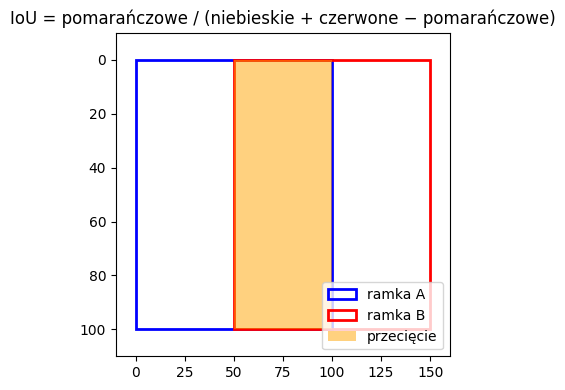

In [35]:
def iou(ramka_a, ramka_b):
    # ramki podajemy jako [x1, y1, x2, y2] — lewy górny i prawy dolny róg
    # 1) prostokąt przecięcia: bierzemy "prawy" brzeg lewej ramki i "lewy" brzeg prawej (i analogicznie w pionie)
    x1 = max(ramka_a[0], ramka_b[0])   # lewy górny róg przecięcia
    y1 = max(ramka_a[1], ramka_b[1])
    x2 = min(ramka_a[2], ramka_b[2])   # prawy dolny róg przecięcia
    y2 = min(ramka_a[3], ramka_b[3])
    # max(0, ...) — jeśli ramki się nie dotykają, "przecięcie" wychodzi ujemne i znaczy zero
    pole_przeciecia = max(0, x2 - x1) * max(0, y2 - y1)
    # 2) pola obu ramek
    pole_a = (ramka_a[2] - ramka_a[0]) * (ramka_a[3] - ramka_a[1])
    pole_b = (ramka_b[2] - ramka_b[0]) * (ramka_b[3] - ramka_b[1])
    # 3) IoU = przecięcie / (suma pól − przecięcie); część wspólna byłaby policzona dwa razy
    return pole_przeciecia / (pole_a + pole_b - pole_przeciecia)

# Test: druga ramka przesunięta o połowę swojej szerokości względem pierwszej
a = [0, 0, 100, 100]
b = [50, 0, 150, 100]
print(f"IoU(a, b) = {iou(a, b):.2f}")
# przecięcie = 50×100 = 5000; pola ramek = 10000 + 10000; IoU = 5000 / 15000 = 0.33

# Rysunek dla lepszego wyczucia:
fig, os = plt.subplots(figsize=(4, 4))
os.add_patch(plt.Rectangle((0, 0), 100, 100, fill=False, color="blue", linewidth=2, label="ramka A"))
os.add_patch(plt.Rectangle((50, 0), 100, 100, fill=False, color="red", linewidth=2, label="ramka B"))
os.add_patch(plt.Rectangle((50, 0), 50, 100, facecolor="orange", alpha=0.5, label="przecięcie"))
os.set_xlim(-10, 160)
os.set_ylim(110, -10)   # odwracamy oś Y, żeby układ był jak na obrazie (y rośnie w dół)
os.legend(loc="lower right")
os.set_title("IoU = pomarańczowe / (niebieskie + czerwone − pomarańczowe)")
plt.tight_layout(); plt.show()

Ramki po NMS: [4, 0]


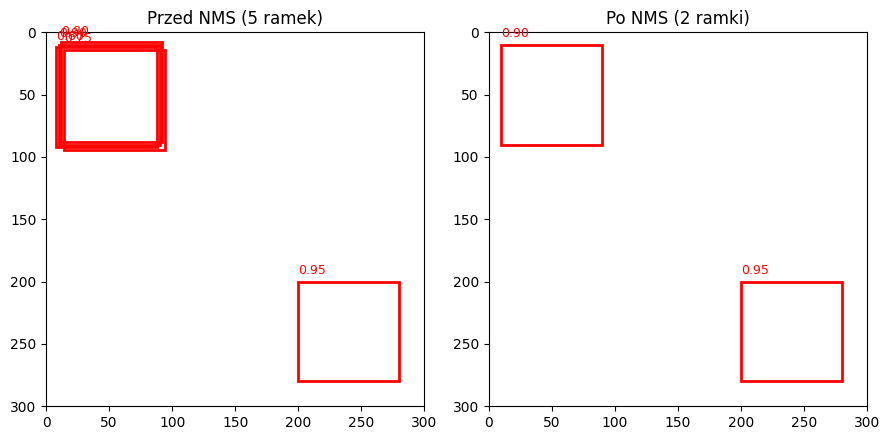

In [36]:
def nms(ramki, pewnosci, prog_iou=0.5):
    # ramki: lista [x1,y1,x2,y2]; pewnosci: lista liczb 0-1;
    # prog_iou: powyżej jakiego IoU dwie ramki uznajemy za duplikaty tego samego obiektu
    # 1) sortujemy indeksy ramek od najpewniejszej do najmniej pewnej
    kolejnosc = sorted(range(len(ramki)), key=lambda i: pewnosci[i], reverse=True)
    wybrane = []
    while kolejnosc:
        najlepszy = kolejnosc.pop(0)   # 2) bierzemy najpewniejszą ramkę i zostawiamy ją na zawsze
        wybrane.append(najlepszy)
        # 3) z puli wyrzucamy wszystkie ramki, które z nią za mocno się pokrywają (duplikaty)
        kolejnosc = [i for i in kolejnosc if iou(ramki[najlepszy], ramki[i]) < prog_iou]
    return wybrane

# Scenariusz: detektor znalazł 5 ramek wokół JEDNEGO kota (klasyczny bałagan przed NMS)
# + 1 ramkę gdzieś indziej na obrazie (inny obiekt).
ramki   = [[10, 10, 90, 90], [12, 8, 92, 88], [14, 14, 94, 94], [8, 12, 88, 92], [200, 200, 280, 280]]
pewnosc = [0.90, 0.80, 0.75, 0.60, 0.95]

pozostale = nms(ramki, pewnosc, prog_iou=0.5)
print("Ramki po NMS:", pozostale)
# Zostają: ramka 4 (osobny obiekt, 0.95) i ramka 0 (kot, 0.90) — reszta to duplikaty kota

# Rysunek: przed i po
fig, osie = plt.subplots(1, 2, figsize=(9, 4.5))
for os, indeksy, tyt in [(osie[0], range(len(ramki)), "Przed NMS (5 ramek)"),
                         (osie[1], pozostale, "Po NMS (2 ramki)")]:
    os.set_xlim(0, 300)
    os.set_ylim(300, 0)   # y rośnie w dół — jak na obrazie
    os.set_title(tyt)
    for i in indeksy:
        x1, y1, x2, y2 = ramki[i]
        os.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2, color="red"))
        os.text(x1, y1 - 6, f"{pewnosc[i]:.2f}", color="red", fontsize=9)
plt.tight_layout(); plt.show()

## 8. Detekcja "ręczna" — progi i kontury (OpenCV)

Zanim sieci neuronowe zawładnęły wizją komputerową, obiekty znajdowano prostszymi metodami. Zobaczmy jedną z nich na naszej scenie — dobrze widać jej siłę i jej granice.

Pomysł:
1. zamieniamy obraz na przestrzeń **HSV** — Hue (odcień), Saturation (nasycenie), Value (jasność). HSV jest wygodny, bo "kolor" siedzi w jednym kanale (H), a jasność w innym (V) — łatwo wybrać "wszystko, co czerwone", niezależnie od oświetlenia,
2. **`cv2.inRange`** — podajemy zakres HSV i dostajemy maskę binarną: 255 tam, gdzie piksel mieści się w zakresie, 0 poza nim,
3. **`cv2.findContours`** — szuka spójnych "wysp" na masce (konturów),
4. wokół każdego konturu rysujemy ramkę (`cv2.boundingRect`).

> Uwaga techniczna: w OpenCV odcień H mieści się w zakresie **0–179** (a nie 0–359), żeby zmieścić go w 8 bitach. Nasza czerwień `(R=200, G=60, B=60)` ma H ≈ 0, S ≈ 178, V ≈ 200.

Znaleziono 2 obiektów: [(180, 140, 80, 60), (30, 40, 80, 60)]


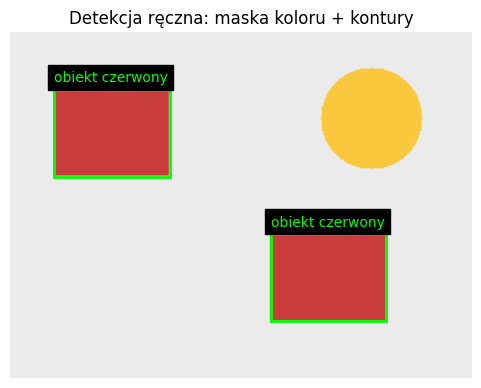

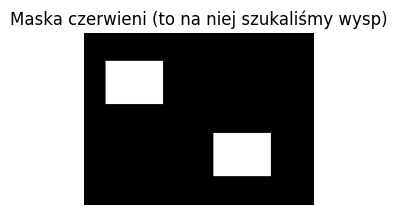

In [37]:
hsv = cv2.cvtColor(scena, cv2.COLOR_RGB2HSV)   # konwersja RGB → HSV
# Zakres wybieramy "z zapasem": H 0-10 (czerwień), nasycenie i jasność od 100 w górę
# (niskie S odrzuca szare tło — tło ma S = 0, bo jest bezbarwne)
maska_czerwieni = cv2.inRange(hsv, (0, 100, 100), (10, 255, 255))

# findContours zwraca listę konturów (każdy kontur = lista punktów jednej "wyspy" na masce)
#   RETR_EXTERNAL        → bierzemy tylko zewnętrzne obrysy (nie dziurki w środku obiektów)
#   CHAIN_APPROX_SIMPLE  → ściskamy punkty konturu (zamiast każdego piksela, tylko rogi)
kontury, _ = cv2.findContours(maska_czerwieni, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

detekcje = []
for kontur in kontury:
    pole = cv2.contourArea(kontur)
    if pole < 500:      # odsiewamy szum — malutkie wyspy to zwykle zakłócenia, nie obiekty
        continue
    x, y, szer, wys = cv2.boundingRect(kontur)   # najmniejszy prostokąt opasujący kontur
    detekcje.append((x, y, szer, wys))

print(f"Znaleziono {len(detekcje)} obiektów: {detekcje}")

fig, os = plt.subplots(figsize=(6, 4.5))
os.imshow(scena)
for x, y, szer, wys in detekcje:
    # plt.Rectangle((x, y), szerokość, wysokość) — (x, y) to lewy górny róg, tak samo liczy boundingRect
    os.add_patch(plt.Rectangle((x, y), szer, wys, fill=False, color="lime", linewidth=2))
    os.text(x, y - 6, "obiekt czerwony", color="lime", fontsize=10, backgroundcolor="black")
os.axis("off")
os.set_title("Detekcja ręczna: maska koloru + kontury")
plt.show()

pokaz_obrazy([maska_czerwieni], ["Maska czerwieni (to na niej szukaliśmy wysp)"])

## 9. Detekcja siecią — Faster R-CNN (gotowe wagi)

Teraz to samo zadanie, ale zrobione przez wytrenowaną sieć. **Faster R-CNN** to klasyczny detektor; jego wagi pochodzą ze zbioru **COCO** (330 tys. zdjęć, 80 klas: osoby, zwierzęta, pojazdy, meble...).

Jak on działa? W skrócie:
1. sieć konwolucyjna przegląda **cały obraz naraz** i wyciąga mapę cech (koniec z przesuwaniem małego okienka piksel po pikselu — to było strasznie wolne),
2. moduł **RPN** (*Region Proposal Network*) zgłasza ok. 2000 "kandydatur": miejsc, gdzie *może coś być* — opiera się na tzw. kotwicach (*anchors*), czyli ramkach o różnych rozmiarach rozmieszczonych w każdym punkcie mapy cech,
3. dla każdej kandydatury druga część sieci precyzuje ramkę i klasyfikuje, co w niej jest.

My musimy tylko: wczytać model, podać obraz jako tensor 0–1 i odczytać wynik. Model zwraca słownik z tensorami `boxes`, `labels`, `scores`.

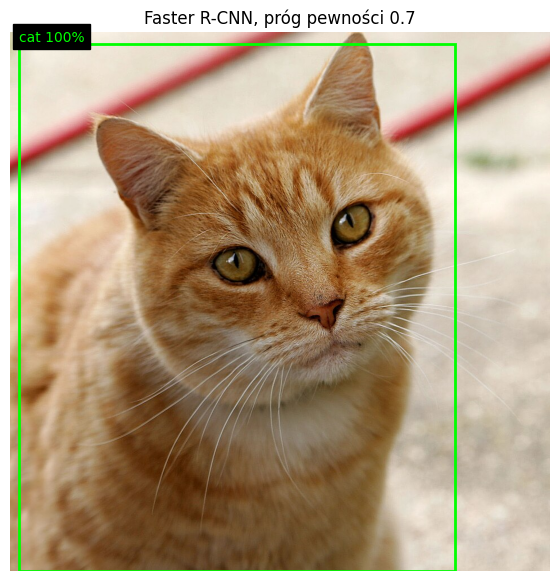

In [38]:
# Wagi wytrenowane na COCO (pierwsze uruchomienie pobiera ~160 MB)
wagi_detektor = torchvision.models.detection.FasterRCNN_ResNet50_FPN_Weights.DEFAULT
detektor = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=wagi_detektor)
detektor.eval()                    # znowu: tryb używania, nie treningu
detektor.to(URZADZENIE)

# Detektor nie wymaga Resize/Normalize — sam skaluje obraz w środku.
# Wymaga tylko: tensor typu float w zakresie 0-1, ułożony (kanały, wysokość, szerokość).
tensor_obrazu = torchvision.transforms.functional.to_tensor(obraz_pil).to(URZADZENIE)

with torch.inference_mode():
    # modele detekcji przyjmują LISTĘ obrazów (partię) i zwracają LISTĘ wyników — po jednym na obraz
    wynik = detektor([tensor_obrazu])[0]

kategorie_coco = wagi_detektor.meta["categories"]   # nazwy klas (indeks 0 = tło, potem 80 klas COCO)

# Filtrujemy: zostawiamy tylko detekcje z pewnością > 0.7. Próg dobieramy według potrzeb:
# niżej = więcej detekcji, ale więcej pomyłek; wyżej = mniej, ale pewniejsze
PROG_PEWNOSCI = 0.7
dobrze = wynik["scores"] > PROG_PEWNOSCI   # maska bitowa: True tam, gdzie pewność wystarcza

fig, os = plt.subplots(figsize=(7, 7))
os.imshow(tensor_obrazu.cpu().permute(1, 2, 0))
# tensor ma kolejność (kanały, wys, szer), a imshow oczekuje (wys, szer, kanały) → permute zamienia wymiary;
# .cpu() = ściągnięcie danych z GPU z powrotem do pamięci zwykłej (matplotlib nie czyta z GPU)

for box, etykieta, pewnosc in zip(wynik["boxes"][dobrze].cpu(),
                                  wynik["labels"][dobrze].cpu(),
                                  wynik["scores"][dobrze].cpu()):
    x1, y1, x2, y2 = box.tolist()          # tensor → zwykłe liczby Pythona
    os.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="lime", linewidth=2))
    os.text(x1, y1 - 5, f"{kategorie_coco[etykieta.item()]} {pewnosc.item():.0%}",
            color="lime", fontsize=10, backgroundcolor="black")
os.axis("off")
os.set_title(f"Faster R-CNN, próg pewności {PROG_PEWNOSCI}")
plt.show()

## 10. Segmentacja — koncepcja

Mamy już pełną hierarchię zadań wizji komputerowej:

| Zadanie | Pytanie | Wynik |
|---|---|---|
| klasyfikacja | co to jest? | 1 etykieta na cały obraz |
| detekcja | co i gdzie (mniej więcej)? | ramki + etykiety |
| **segmentacja** | co dokładnie, piksel po pikselu? | **maska**: etykieta dla każdego piksela |

Segmentacja dzieli się na dwa warianty:
- **semantyczna** — każdy piksel dostaje etykietę klasy, ale nie interesuje nas, do którego obiektu należy. Dwa psy na zdjęciu = jeden wielki obszar "pies",
- **instancji** (*instance segmentation*) — dodatkowo rozdzielamy osobne obiekty tej samej klasy. Dwa psy = dwie osobne maski.

Najpierw segmentacja "ręczna" — naszym starym znajomym: progiem w HSV. Na naszej scenie zamaskujemy wszystko, co czerwone. Zauważ: maska obejmie **oba czerwone prostokąty naraz i nie będzie wiedziała, że to dwa osobne obiekty** — to właśnie segmentacja semantyczna.

Maska obejmuje 12.5% powierzchni obrazu (dwa czerwone prostokąty RAZEM — maska ich nie rozróżnia)


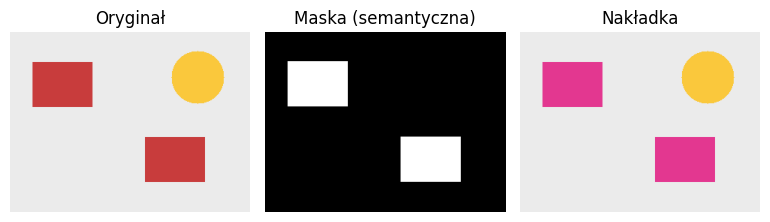

In [39]:
# Ta sama maska co w sekcji 8 — teraz patrzymy na nią jak na segmentację semantyczną
maska = cv2.inRange(hsv, (0, 100, 100), (10, 255, 255)) > 0
# > 0 zamienia 0/255 na False/True — maska bitowa jest wygodniejsza do nakładania i liczenia

# Nakładka: obraz oryginalny "prześwitujący" przez półprzezroczysty kolor maski
nakladka = scena.astype(np.float32) / 255.0       # przechodzimy na wartości 0-1 (wygodne do mieszania kolorów)
KOLOR_MASKI = np.array([1.0, 0.2, 0.9])           # fiolet w RGB (0-1)
ALPHA = 0.5                                       # 0 = maska niewidoczna, 1 = całkiem zakrywa obraz
nakladka[maska] = nakladka[maska] * (1 - ALPHA) + KOLOR_MASKI * ALPHA
# klasyczne mieszanie alfa: wynik = tło * (1 - α) + pierwsza_warstwa * α

procent = maska.mean() * 100   # średnia maski bitowej = odsetek pikseli True → od razu mamy % powierzchni
print(f"Maska obejmuje {procent:.1f}% powierzchni obrazu (dwa czerwone prostokąty RAZEM — maska ich nie rozróżnia)")

pokaz_obrazy([scena, maska.astype(np.uint8) * 255, (nakladka * 255).astype(np.uint8)],
             ["Oryginał", "Maska (semantyczna)", "Nakładka"])

## 11. Segmentacja siecią — Mask R-CNN (gotowe wagi)

**Mask R-CNN** to Faster R-CNN + jedna dodatkowa gałąź: dla każdej wykrytej ramki sieć dodatkowo generuje **maskę pikselową** obiektu. Dzięki temu dostajemy segmentację **instancji** — dwa czerwone prostokąty (a na prawdziwym zdjęciu: dwie osoby) dostaną osobne maski.

Wynik modelu to ten sam słownik co w detekcji + tensor `masks`: dla każdego obiektu mapa o rozmiarze zdjęcia, w której wartości 0–1 mówią, jak bardzo dany piksel "należy" do obiektu. Progiem 0.5 zamieniamy ją na maskę tak/nie.

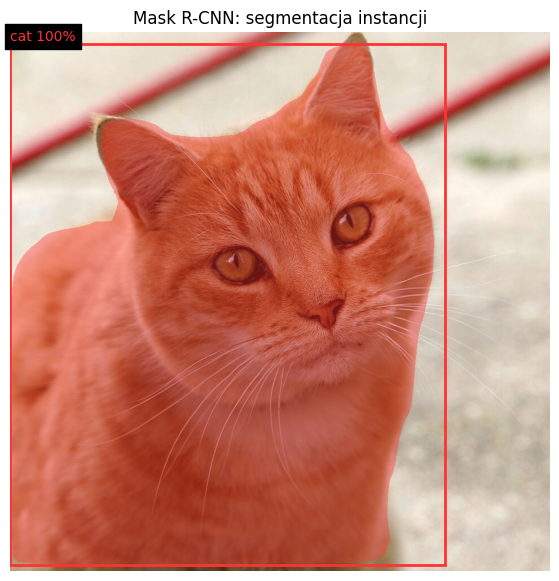

In [40]:
wagi_maski = torchvision.models.detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT
segmentator = torchvision.models.detection.maskrcnn_resnet50_fpn(weights=wagi_maski)
segmentator.eval().to(URZADZENIE)   # eval() zwraca sam model, więc można od razu dołańcuchować .to()

with torch.inference_mode():
    wynik = segmentator([tensor_obrazu])[0]   # ten sam format wejścia co Faster R-CNN

PALETA = [[1.0, 0.2, 0.2], [0.2, 0.6, 1.0], [0.2, 1.0, 0.4], [1.0, 0.9, 0.2], [1.0, 0.2, 0.9]]

# Najpierw liczymy nakładkę i zbieramy ramki do narysowania, a rysujemy na końcu —
# inaczej matplotlib pokazałby obraz sprzed nałożenia masek
rysunki = []
nakladka = tensor_obrazu.cpu().permute(1, 2, 0).numpy().copy()
# .copy() — pracujemy na kopii, żeby nie zmieniać oryginalnego tensora z obrazem

for i, (box, etykieta, pewnosc, maska_miekka) in enumerate(zip(
        wynik["boxes"].cpu(), wynik["labels"].cpu(),
        wynik["scores"].cpu(), wynik["masks"].cpu())):
    if pewnosc < 0.7:                        # ten sam próg pewności co w detekcji
        continue
    # masks mają kształt (1, H, W) → [0] zdejmie pierwszy wymiar; próg 0.5 = "piksel należy do obiektu"
    maska_twarda = (maska_miekka[0] > 0.5).numpy()   # tensor → macierz numpy (do indeksowania nakładki)
    kolor = PALETA[i % len(PALETA)]          # kolejne obiekty dostają kolejne kolory (modulo = wracamy do początku)
    nakladka[maska_twarda] = nakladka[maska_twarda] * 0.6 + np.array(kolor) * 0.4   # mieszanie alfa, α = 0.4
    x1, y1, x2, y2 = box.tolist()
    rysunki.append(((x1, y1, x2, y2), kolor, f"{kategorie_coco[etykieta.item()]} {pewnosc.item():.0%}"))

fig, os = plt.subplots(figsize=(7, 7))
os.imshow(nakladka)
for (x1, y1, x2, y2), kolor, opis in rysunki:
    os.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=kolor, linewidth=2))
    os.text(x1, y1 - 5, opis, color=kolor, fontsize=10, backgroundcolor="black")
os.axis("off")
os.set_title("Mask R-CNN: segmentacja instancji")
plt.show()

## 12. Podsumowanie

| Model | Zadanie | Wejście | Wyjście | Wagi |
|---|---|---|---|---|
| ResNet-18 | klasyfikacja | obraz 224×224, znormalizowany | 1000 liczb → prawdopodobieństwa klas | ImageNet (~45 MB) |
| Faster R-CNN | detekcja | tensor 0–1 | ramki + etykiety + pewności | COCO (~160 MB) |
| Mask R-CNN | segmentacja instancji | tensor 0–1 | to samo + maski pikselowe | COCO (~170 MB) |

**Najważniejsze idee z tego notebooka:**

1. Obraz to macierz liczb — wszystkie "magiczne" operacje wizji komputerowej to operacje na tych liczbach.
2. Konwolucja = małe jądro przesuwane po obrazie; w CNN liczby w jądrach nie są pisane ręcznie, tylko **uczą się** z danych.
3. CNN buduje hierarchię: krawędzie → kształty → obiekty; Pool zmniejsza obraz i daje odporność na przesunięcia.
4. Detekcja i segmentacja to "klasyfikacja + gdzie": IoU mierzy jakość ramek, NMS czyści duplikaty.
5. Gotowe wagi (*pretrained*) pozwalają używać potężnych modeli bez treningu — a przy własnym zadaniu można je **dotrenować** (transfer learning).
